In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,precision_score, recall_score, f1_score

In [4]:
df = pd.read_csv(r'C:\Users\dell\data-science-ai\customer-churn-prediction\data\Churn_Modelling.csv')

In [5]:
print(df.shape)
df.head()

(10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [6]:
X = df.drop(columns=["Exited", "RowNumber", "CustomerId", "Surname"])
y = df["Exited"]

In [7]:
print("Features:", X.shape)
print("Target:", y.shape)
print(y.value_counts())

Features: (10000, 10)
Target: (10000,)
Exited
0    7963
1    2037
Name: count, dtype: int64


In [8]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [9]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (7000, 10)
Validation: (1500, 10)
Test: (1500, 10)


In [10]:
numerical_cols = X_train.select_dtypes(include="number").columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical columns: ['Geography', 'Gender']


In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

In [12]:
# Model 1 : Logistic Regression
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

In [13]:
# Model 2
rf_model = Pipeline(steps = [
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [14]:
lr_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['CreditScore','Geography','Gender',...,'HasCrCard','IsActiveMember', 'EstimatedSalary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [15]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['CreditScore','Geography','Gender',...,'HasCrCard','IsActiveMember', 'EstimatedSalary']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder

In [16]:
y_val_pred_lr = lr_model.predict(X_val)
y_val_pred_rf = rf_model.predict(X_val)

In [17]:
print("Logistic Regression:")
print(confusion_matrix(y_val, y_val_pred_lr))
print("Random Forest:")
print(confusion_matrix(y_val, y_val_pred_rf))

Logistic Regression:
[[851 343]
 [ 80 226]]
Random Forest:
[[1099   95]
 [ 125  181]]


In [18]:
print("Logistic Regression:")
print(classification_report(y_val, y_val_pred_lr))
print("Random Forest:")
print(classification_report(y_val, y_val_pred_rf))

Logistic Regression:
              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1194
           1       0.40      0.74      0.52       306

    accuracy                           0.72      1500
   macro avg       0.66      0.73      0.66      1500
weighted avg       0.81      0.72      0.74      1500

Random Forest:
              precision    recall  f1-score   support

           0       0.90      0.92      0.91      1194
           1       0.66      0.59      0.62       306

    accuracy                           0.85      1500
   macro avg       0.78      0.76      0.77      1500
weighted avg       0.85      0.85      0.85      1500



In [19]:
y_val_proba_rf = rf_model.predict_proba(X_val)[:, 1]

y_val_proba_rf[:10]

array([0.54 , 0.01 , 0.33 , 0.095, 0.63 , 0.33 , 0.125, 0.175, 0.11 ,
       0.485])

In [20]:
thresholds = np.arange(0.30, 0.61, 0.01)

results = []

for threshold in thresholds:
    y_pred = (y_val_proba_rf >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred)
    })

results_df = pd.DataFrame(results)

results_df.loc[results_df["f1"].idxmax()]

threshold    0.470000
accuracy     0.846667
precision    0.621795
recall       0.633987
f1           0.627832
Name: 17, dtype: float64

In [21]:
# Predict probabilities on the test set
y_test_proba_rf = rf_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
y_test_pred_rf = (y_test_proba_rf >= 0.47).astype(int)

# Evaluate final performance
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_rf))

print("Accuracy:", accuracy_score(y_test, y_test_pred_rf))

Confusion Matrix:
[[1054  141]
 [ 115  190]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.88      0.89      1195
           1       0.57      0.62      0.60       305

    accuracy                           0.83      1500
   macro avg       0.74      0.75      0.74      1500
weighted avg       0.84      0.83      0.83      1500

Accuracy: 0.8293333333333334


In [22]:
y_val_pred_rf_default = rf_model.predict(X_val)
print("Validation F1-score:", f1_score(y_val, y_val_pred_rf_default))

Validation F1-score: 0.6219931271477663


In [23]:
for depth in [None, 5, 10, 20]:
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=depth,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)

    print(
        f"Max depth: {depth} | "
        f"F1-score: {f1_score(y_val, y_pred):.3f}"
    )

Max depth: None | F1-score: 0.622
Max depth: 5 | F1-score: 0.627
Max depth: 10 | F1-score: 0.638
Max depth: 20 | F1-score: 0.629


In [26]:
best_rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=500,
        max_depth=10,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

best_rf_model.fit(X_train, y_train)

y_val_pred_best = best_rf_model.predict(X_val)

print("Validation F1-score:",
      f1_score(y_val, y_val_pred_best))

print("Validation accuracy:",
      accuracy_score(y_val, y_val_pred_best))

Validation F1-score: 0.6501457725947521
Validation accuracy: 0.84


In [28]:
y_val_proba_best = best_rf_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.30, 0.71, 0.01)
results = []

for threshold in thresholds:
    y_pred = (y_val_proba_best >= threshold).astype(int)

    results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
        "f1": f1_score(y_val, y_pred)
    })

results_df = pd.DataFrame(results)

best_threshold_result = results_df.loc[results_df["f1"].idxmax()]
print(best_threshold_result)

threshold    0.540000
accuracy     0.853333
precision    0.626471
recall       0.696078
f1           0.659443
Name: 24, dtype: float64


In [29]:
# Predict churn probabilities on the test set
y_test_proba_best = best_rf_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
y_test_pred_best = (y_test_proba_best >= 0.54).astype(int)

# Final evaluation
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_best))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_best))

print("Accuracy:", accuracy_score(y_test, y_test_pred_best))

Confusion Matrix:
[[1053  142]
 [ 100  205]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.88      0.90      1195
           1       0.59      0.67      0.63       305

    accuracy                           0.84      1500
   macro avg       0.75      0.78      0.76      1500
weighted avg       0.85      0.84      0.84      1500

Accuracy: 0.8386666666666667


In [30]:
feature_names = best_rf_model.named_steps["preprocessor"].get_feature_names_out()

importances = best_rf_model.named_steps["classifier"].feature_importances_

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

feature_importance.head(10)

,feature,importance
1,num__Age,0.308991
4,num__NumOfProducts,0.202197
3,num__Balance,0.118736
7,num__EstimatedSalary,0.080790
0,num__CreditScore,0.080313
6,num__IsActiveMember,0.054435
2,num__Tenure,0.045863
9,cat__Geography_Germany,0.044710
8,cat__Geography_France,0.015133
12,cat__Gender_Male,0.014363


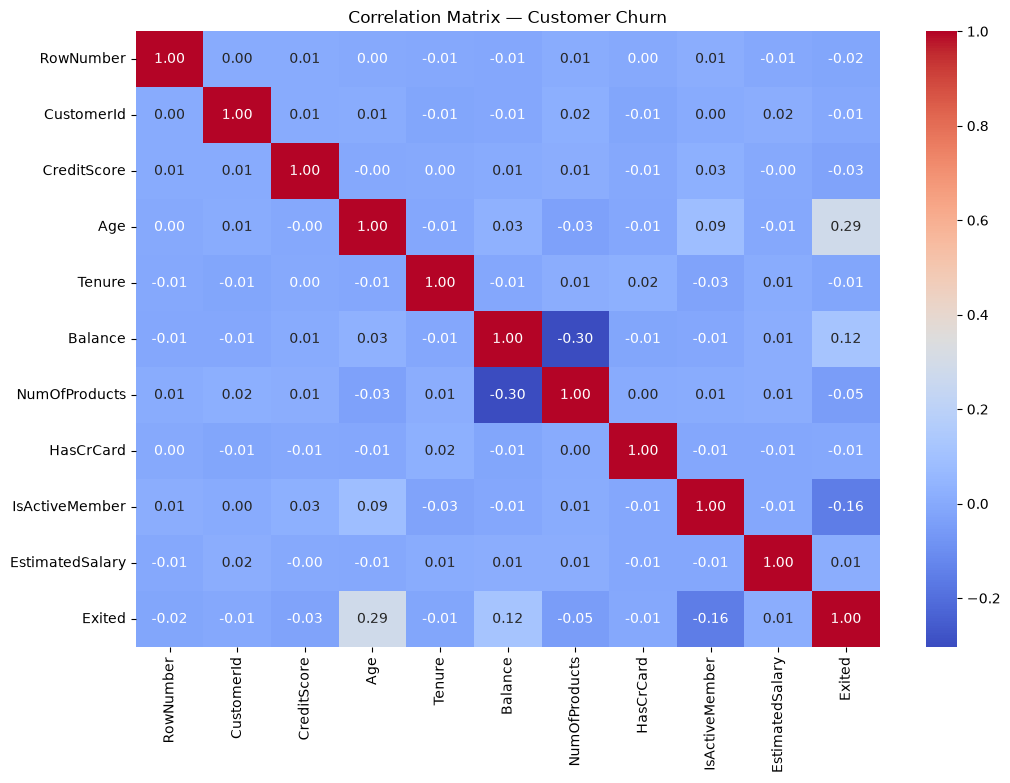

In [31]:
correlation_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix — Customer Churn")
plt.show()